# Setup

In [1]:
import sys
from pathlib import Path

# Make eval_utils importable whether the kernel starts in repo root or notebooks/.
_here = Path.cwd()
for cand in (_here, _here / "notebooks", _here.parent):
    if (cand / "eval_utils.py").exists():
        sys.path.insert(0, str(cand))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

import eval_utils as ev
from eval_utils import (
    SPLITS, NORMAL_SPLIT, SHIFT_SPLIT, ROBUST_METRICS, METRIC_LABELS,
    SPLIT_COLORS, CLASS_NAMES_FULL,
)

ev.apply_style()
FIG_DIR = ev.make_fig_dir("figures")
TABLE_DIR = ev.make_table_dir("tables")  # xlsx exports for PowerPoint/Word
SAVE_FIGS = True

In [2]:
# Edit here to point elsewhere or widen the selection.
ENTITY, PROJECT, RUN_TAG = ev.ENTITY, ev.PROJECT, ev.RUN_TAG   # ("trash-busters", "trash-busters", "core")

runs = ev.fetch_runs(ENTITY, PROJECT, RUN_TAG)
runs = [r for r in runs if "softmax" not in r.tags]
ev.describe_runs(runs)

# Core metrics + per-sample confusion frames (shared by both notebooks).
metrics_long, confusion_frames = ev.build_metrics(runs)

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.


Found 4 run(s):
  - baseline_final                 model=baseline       classes=6 state=finished tags=['core']
  - mlp_mixer_final                model=mlp_mixer      classes=6 state=finished tags=['core']
  - convnext_tiny_final            model=convnext_tiny  classes=6 state=finished tags=['core']
  - deit_final                     model=deit           classes=6 state=finished tags=['core']


wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  


# Metrics

In [3]:
metrics_long

,run,model,split,split_label,accuracy,macro_f1,balanced_acc,mcc,n
0,baseline_final,baseline,test,Normal test,0.7950,0.7946,0.7954,0.7543,4478
1,baseline_final,baseline,custom_test,Custom (domain shift),0.2902,0.2737,0.3506,0.1859,348
2,mlp_mixer_final,mlp_mixer,test,Normal test,0.9319,0.9319,0.9320,0.9183,4478
3,mlp_mixer_final,mlp_mixer,custom_test,Custom (domain shift),0.3276,0.3759,0.4153,0.2864,348
4,convnext_tiny_final,convnext_tiny,test,Normal test,0.9455,0.9455,0.9456,0.9346,4478
5,convnext_tiny_final,convnext_tiny,custom_test,Custom (domain shift),0.4080,0.4529,0.5117,0.3693,348
6,deit_final,deit,test,Normal test,0.8964,0.8963,0.8966,0.8757,4478
7,deit_final,deit,custom_test,Custom (domain shift),0.3448,0.3758,0.4192,0.2787,348


In [4]:
# Sanity check: CSV-derived accuracy/macro_f1 vs the values wandb logged.
checks = []
for run in runs:
    for split in SPLITS:
        m = metrics_long[(metrics_long.run == run.name) & (metrics_long.split == split)]
        if m.empty:
            continue
        s = run.summary
        checks.append({
            "run": run.name, "split": split,
            "acc_csv": m.accuracy.iloc[0], "acc_logged": s.get(f"{split}/acc", np.nan),
            "f1_csv": m.macro_f1.iloc[0], "f1_logged": s.get(f"{split}/f1_macro", np.nan),
        })
check_df = pd.DataFrame(checks)
if not check_df.empty:
    check_df["acc_delta"] = (check_df.acc_csv - check_df.acc_logged).abs()
    check_df["f1_delta"] = (check_df.f1_csv - check_df.f1_logged).abs()
check_df

,run,split,acc_csv,acc_logged,f1_csv,f1_logged,acc_delta,f1_delta
0,baseline_final,test,0.7950,0.7950,0.7946,0.7946,0.0000,0.0000
1,baseline_final,custom_test,0.2902,0.2902,0.2737,0.2737,0.0000,0.0000
2,mlp_mixer_final,test,0.9319,0.9319,0.9319,0.9319,0.0000,0.0000
3,mlp_mixer_final,custom_test,0.3276,0.3276,0.3759,0.3759,0.0000,0.0000
4,convnext_tiny_final,test,0.9455,0.9455,0.9455,0.9455,0.0000,0.0000
5,convnext_tiny_final,custom_test,0.4080,0.4080,0.4529,0.4529,0.0000,0.0000
6,deit_final,test,0.8964,0.8964,0.8963,0.8963,0.0000,0.0000
7,deit_final,custom_test,0.3448,0.3448,0.3758,0.3758,0.0000,0.0000


# Acc

,accuracy,macro_f1,balanced_acc,mcc
model,,,,
convnext_tiny,0.9455,0.9455,0.9456,0.9346
mlp_mixer,0.9319,0.9319,0.9320,0.9183
deit,0.8964,0.8963,0.8966,0.8757
baseline,0.7950,0.7946,0.7954,0.7543


saved tables\normal_headline_metrics.xlsx
saved figures\normal_accuracy.png


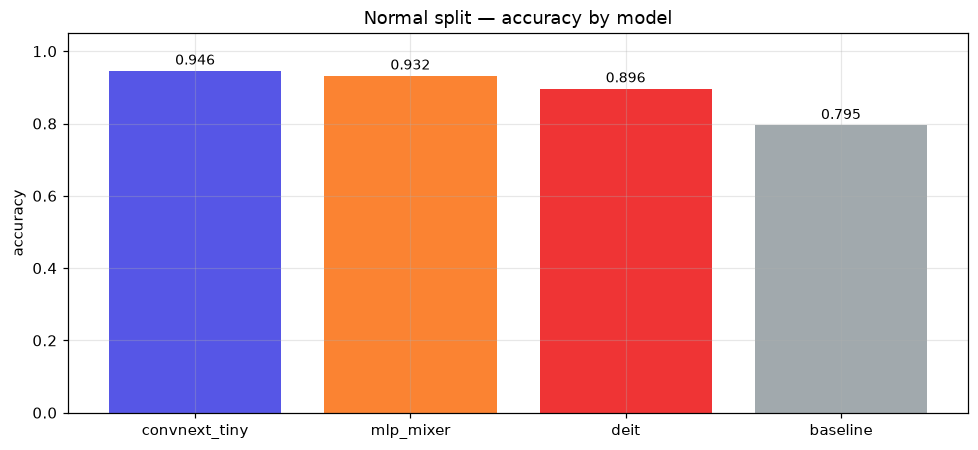

In [5]:
normal = metrics_long[metrics_long.split == NORMAL_SPLIT].set_index("model")
normal_view = normal[["accuracy"] + ROBUST_METRICS].sort_values("accuracy", ascending=False)
ev.show_table(normal_view, "normal_headline_metrics", TABLE_DIR)

fig, ax = plt.subplots(figsize=(1.5 * len(normal_view) + 3, 4.2))
bars = ax.bar(normal_view.index, normal_view["accuracy"], color=ev.model_palette(normal_view.index))
ax.bar_label(bars, fmt="%.3f", fontsize=9, padding=2)
ax.set_ylim(0, 1.05); ax.set_ylabel("accuracy")
ax.set_title("Normal split — accuracy by model")
fig.tight_layout(); ev.savefig(fig, "normal_accuracy", FIG_DIR, SAVE_FIGS); plt.show()

## Metrics per Model

,accuracy,macro_f1,balanced_acc,mcc
model,,,,
convnext_tiny,0.4080,0.4529,0.5117,0.3693
mlp_mixer,0.3276,0.3759,0.4153,0.2864
deit,0.3448,0.3758,0.4192,0.2787
baseline,0.2902,0.2737,0.3506,0.1859


saved tables\shift_robust_metrics.xlsx
saved figures\shift_robust_metrics.png


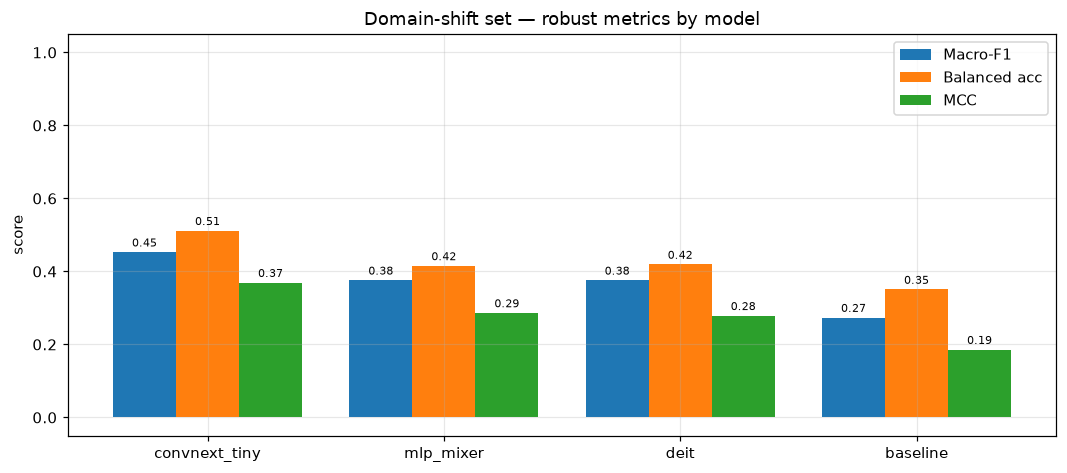

In [6]:
shift = metrics_long[metrics_long.split == SHIFT_SPLIT].set_index("model")
shift_view = shift[["accuracy"] + ROBUST_METRICS].sort_values("macro_f1", ascending=False)
ev.show_table(shift_view, "shift_robust_metrics", TABLE_DIR)

to_plot = ["macro_f1", "balanced_acc", "mcc"]
models = list(shift_view.index)
x = np.arange(len(models)); width = 0.8 / len(to_plot)
fig, ax = plt.subplots(figsize=(1.7 * len(models) + 3, 4.4))
for i, m in enumerate(to_plot):
    bars = ax.bar(x + i * width, shift_view[m].values, width, label=METRIC_LABELS[m])
    ax.bar_label(bars, fmt="%.2f", fontsize=7, padding=2)
ax.set_xticks(x + width * (len(to_plot) - 1) / 2); ax.set_xticklabels(models)
ax.set_ylim(-0.05, 1.05); ax.set_ylabel("score")
ax.set_title("Domain-shift set — robust metrics by model"); ax.legend()
fig.tight_layout(); ev.savefig(fig, "shift_robust_metrics", FIG_DIR, SAVE_FIGS); plt.show()

## Difference between sets

In [ ]:
for metric in ["accuracy", "macro_f1"]:
    ev.show_table(ev.gap_table(metrics_long, metric), f"gap_{metric}", TABLE_DIR)

saved figures\generalization_gap.png


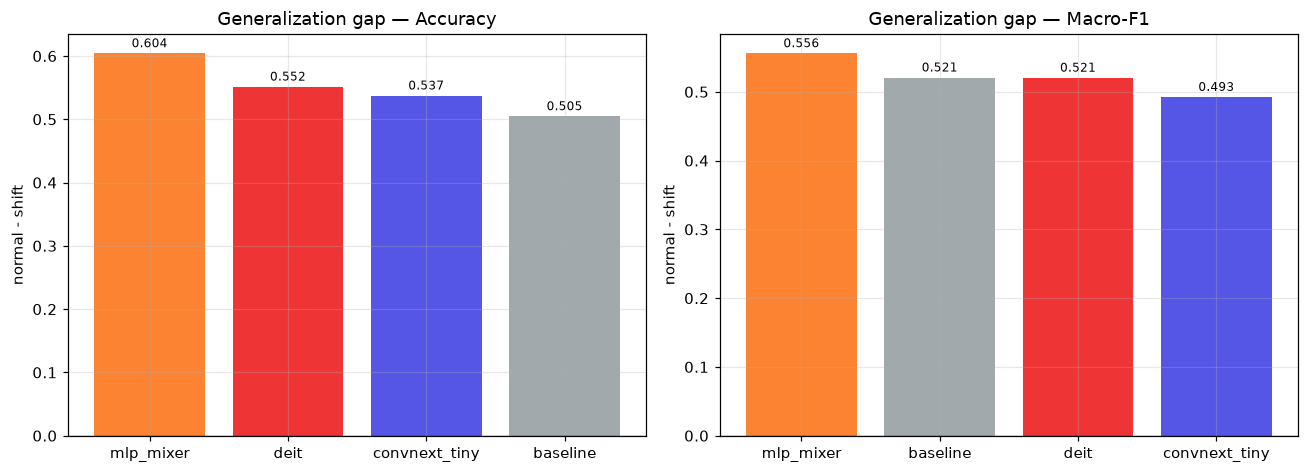

saved figures\slope_f1_gap.png


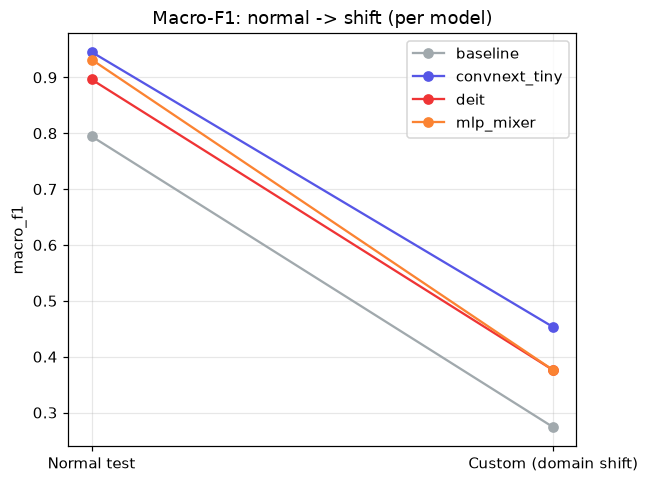

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, metric in zip(axes, ["accuracy", "macro_f1"]):
    g = ev.gap_table(metrics_long, metric)
    bars = ax.bar(g.index, g["gap"], color=ev.model_palette(g.index))
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"Generalization gap — {METRIC_LABELS[metric]}")
    ax.set_ylabel("normal - shift")
fig.tight_layout(); ev.savefig(fig, "generalization_gap", FIG_DIR, SAVE_FIGS); plt.show()

fig, ax = plt.subplots(figsize=(6, 4.5))
for model in sorted(metrics_long.model.unique()):
    sub = metrics_long[metrics_long.model == model].set_index("split")
    if {NORMAL_SPLIT, SHIFT_SPLIT}.issubset(sub.index):
        ax.plot([0, 1], [sub.loc[NORMAL_SPLIT, "macro_f1"], sub.loc[SHIFT_SPLIT, "macro_f1"]],
                marker="o", label=model, color=ev.model_palette([model])[0])
ax.set_xticks([0, 1]); ax.set_xticklabels([SPLITS[NORMAL_SPLIT], SPLITS[SHIFT_SPLIT]])
ax.set_ylabel("macro_f1"); ax.set_title("Macro-F1: normal -> shift (per model)")
ax.legend(); fig.tight_layout(); ev.savefig(fig, "slope_f1_gap", FIG_DIR, SAVE_FIGS); plt.show()

## Validation

In [9]:
histories = {run.name: ev.get_history(run) for run in runs}

gap_rows = []
for run in runs:
    h = histories[run.name]
    if h.empty or "val/acc" not in h.columns:
        continue
    last = h.dropna(subset=["val/acc"]).iloc[-1]
    gap_rows.append({
        "model": ev.model_label(run),
        "train_acc": last.get("train/acc", np.nan), "val_acc": last.get("val/acc", np.nan),
        "acc_gap": last.get("train/acc", np.nan) - last.get("val/acc", np.nan),
        "train_loss": last.get("train/loss", np.nan), "val_loss": last.get("val/loss", np.nan),
        "loss_gap": last.get("val/loss", np.nan) - last.get("train/loss", np.nan),
    })
fit_df = pd.DataFrame(gap_rows).set_index("model") if gap_rows else pd.DataFrame()
if fit_df.empty:
    print("(no epoch history available)")
else:
    ev.show_table(fit_df, "train_val_fit", TABLE_DIR)

,train_acc,val_acc,acc_gap,train_loss,val_loss,loss_gap
model,,,,,,
baseline,0.7891,0.7936,-0.0045,0.6052,0.5768,-0.0284
mlp_mixer,0.9989,0.9354,0.0635,0.0055,0.2513,0.2458
convnext_tiny,0.9985,0.9455,0.0530,0.0138,0.1949,0.1811
deit,0.9823,0.8952,0.0870,0.0793,0.3488,0.2695


saved tables\train_val_fit.xlsx


saved figures\curve_val_loss.png


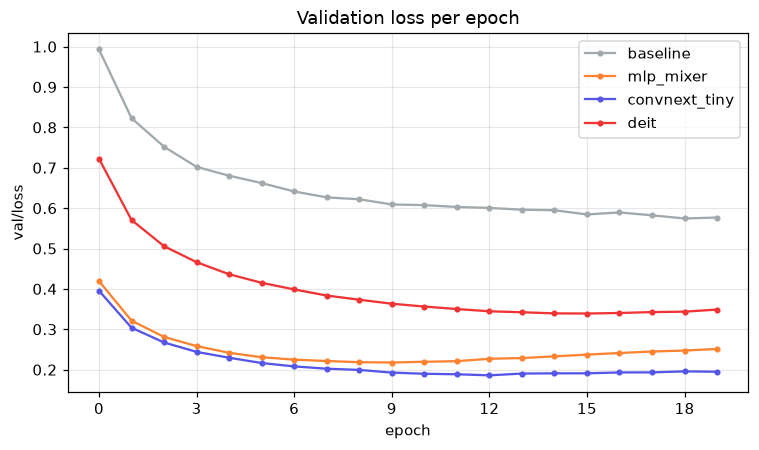

saved figures\curve_val_acc.png


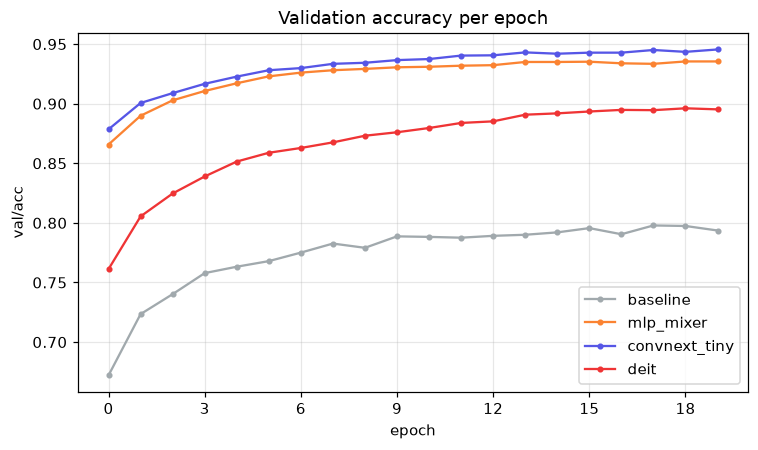

In [10]:
def plot_curves(metric, title, fname):
    fig, ax = plt.subplots(figsize=(7, 4.2)); plotted = False
    for run in runs:
        h = histories[run.name]
        if metric in h.columns and "epoch" in h.columns and h[metric].notna().any():
            ax.plot(h["epoch"], h[metric], marker=".", label=ev.model_label(run), color=ev.model_palette([ev.model_label(run)])[0]); plotted = True
    if not plotted:
        plt.close(fig); print(f"(no history for {metric})"); return
    ax.set_xlabel("epoch"); ax.set_ylabel(metric); ax.set_title(title)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True)); ax.legend()
    fig.tight_layout(); ev.savefig(fig, fname, FIG_DIR, SAVE_FIGS); plt.show()


plot_curves("val/loss", "Validation loss per epoch", "curve_val_loss")
plot_curves("val/acc", "Validation accuracy per epoch", "curve_val_acc")

# Macro F1

,Accuracy (Custom (domain shift)),Accuracy (Normal test),Macro-F1 (Custom (domain shift)),Macro-F1 (Normal test),MCC (Custom (domain shift)),MCC (Normal test),Macro-F1 gap
model,,,,,,,
convnext_tiny,0.4080,0.9455,0.4529,0.9455,0.3693,0.9346,0.4925
mlp_mixer,0.3276,0.9319,0.3759,0.9319,0.2864,0.9183,0.5561
deit,0.3448,0.8964,0.3758,0.8963,0.2787,0.8757,0.5206
baseline,0.2902,0.7950,0.2737,0.7946,0.1859,0.7543,0.5208


saved tables\scoreboard.xlsx
saved figures\scoreboard_f1.png


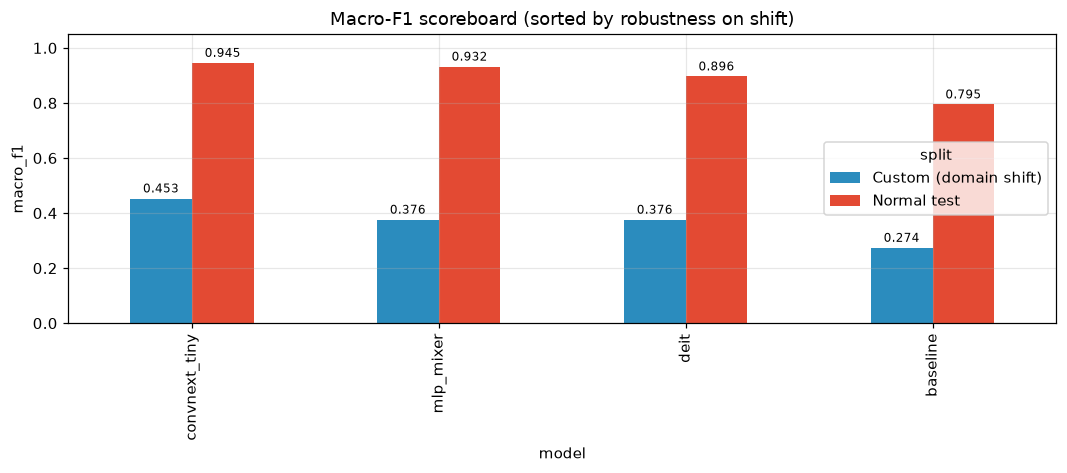

Most robust under domain shift (macro_f1 on shift): convnext_tiny


In [11]:
board = metrics_long.pivot_table(index="model", columns="split",
                                 values=["accuracy", "macro_f1", "mcc"])
board.columns = [f"{METRIC_LABELS[m]} ({SPLITS[s]})" for m, s in board.columns]
board["Macro-F1 gap"] = ev.gap_table(metrics_long, "macro_f1")["gap"]

sort_col = f"Macro-F1 ({SPLITS[SHIFT_SPLIT]})"
if sort_col in board.columns:
    board = board.sort_values(sort_col, ascending=False)
ev.show_table(board, "scoreboard", TABLE_DIR)

comp = metrics_long.pivot_table(index="model", columns="split", values="macro_f1")
comp = comp.rename(columns=SPLITS).sort_values(SPLITS[SHIFT_SPLIT], ascending=False)
ax = comp.plot(kind="bar", figsize=(1.7 * len(comp) + 3, 4.4),
               color=[SPLIT_COLORS[NORMAL_SPLIT], SPLIT_COLORS[SHIFT_SPLIT]])
ax.set_ylabel("macro_f1"); ax.set_ylim(0, 1.05)
ax.set_title("Macro-F1 scoreboard (sorted by robustness on shift)"); ax.legend(title="split")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
fig = ax.get_figure(); fig.tight_layout()
ev.savefig(fig, "scoreboard_f1", FIG_DIR, SAVE_FIGS); plt.show()
print(f"Most robust under domain shift (macro_f1 on shift): {comp.index[0]}")

# AUROC, ECE, SCE
(needs softmax data)

In [12]:
# AUROC/ECE come from the separate `softmax` runs (scripts/log_prob_metrics.py).
prob_runs = ev.fetch_softmax_runs()
if not prob_runs:
    print("No 'softmax' runs found -- run scripts/log_prob_metrics.py first. "
          "Skipping probability metrics.")
    prob_metrics = pd.DataFrame()
else:
    print(f"Found {len(prob_runs)} softmax run(s): {[r.name for r in prob_runs]}")
    prob_metrics = ev.build_probability_metrics(prob_runs)
prob_metrics

Found 4 softmax run(s): ['baseline_final_softmax', 'mlp_mixer_final_softmax', 'convnext_tiny_final_softmax', 'deit_final_softmax']


wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  


,run,model,source_run_name,split,split_label,auroc_macro_ovr,ece,sce,auroc_cardboard,auroc_glass,auroc_metal,auroc_paper,auroc_plastic,auroc_trash
0,baseline_final_softmax,baseline,baseline_final,test,Normal test,0.9626,0.0228,-0.0226,0.9821,0.9785,0.9683,0.9445,0.9362,0.9662
1,baseline_final_softmax,baseline,baseline_final,custom_test,Custom (domain shift),0.8053,0.3704,0.3704,0.8627,0.8262,0.8020,0.7281,0.6607,0.9523
2,mlp_mixer_final_softmax,mlp_mixer,mlp_mixer_final,test,Normal test,0.9947,0.0404,0.0398,0.9973,0.9980,0.9979,0.9899,0.9905,0.9949
3,mlp_mixer_final_softmax,mlp_mixer,mlp_mixer_final,custom_test,Custom (domain shift),0.7797,0.5333,0.5333,0.7298,0.8429,0.8632,0.6856,0.6570,0.8994
4,convnext_tiny_final_softmax,convnext_tiny,convnext_tiny_final,test,Normal test,0.9961,0.0238,0.0224,0.9975,0.9985,0.9982,0.9928,0.9928,0.9965
5,convnext_tiny_final_softmax,convnext_tiny,convnext_tiny_final,custom_test,Custom (domain shift),0.8527,0.4590,0.4575,0.8935,0.9282,0.9172,0.7483,0.6984,0.9307
6,deit_final_softmax,deit,deit_final,test,Normal test,0.9861,0.0398,0.0387,0.9950,0.9929,0.9927,0.9790,0.9718,0.9852
7,deit_final_softmax,deit,deit_final,custom_test,Custom (domain shift),0.7836,0.4986,0.4921,0.7987,0.8135,0.8204,0.7480,0.6591,0.8620


auroc_macro_ovr                               ece  \
split_label   Custom (domain shift) Normal test Custom (domain shift)   
model                                                                   
baseline                     0.8053      0.9626                0.3704   
convnext_tiny                0.8527      0.9961                0.4590   
deit                         0.7836      0.9861                0.4986   
mlp_mixer                    0.7797      0.9947                0.5333   

                           
split_label   Normal test  
model                      
baseline           0.0228  
convnext_tiny      0.0238  
deit               0.0398  
mlp_mixer          0.0404

saved tables\auroc_ece.xlsx
saved figures\auroc_ece.png


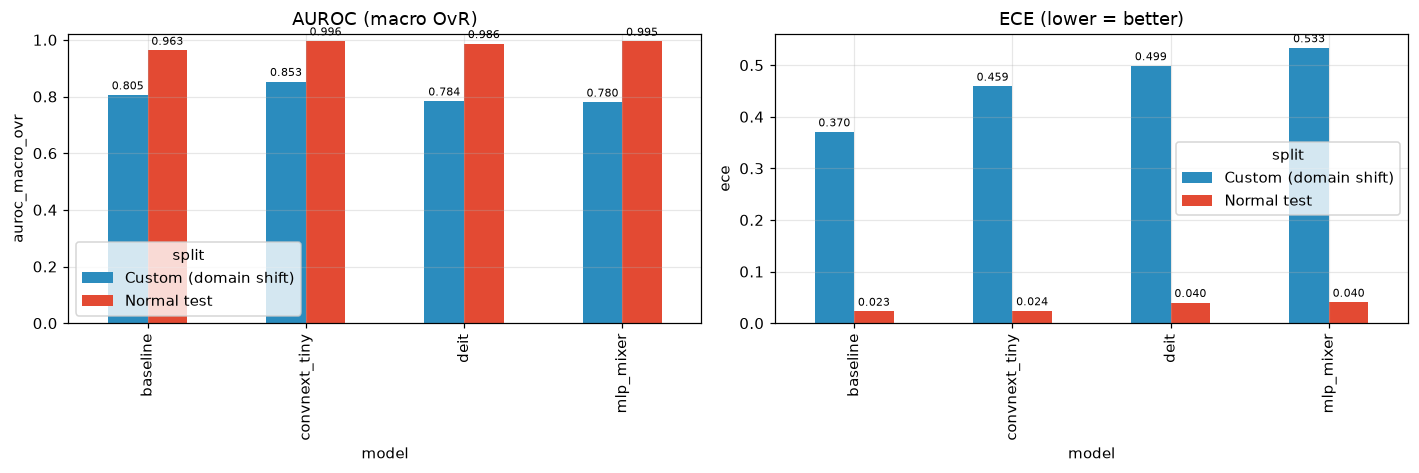

In [13]:
if not prob_metrics.empty:
    view = prob_metrics.pivot_table(
        index="model", columns="split_label", values=["auroc_macro_ovr", "ece"])
    ev.show_table(view, "auroc_ece", TABLE_DIR)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    for ax, metric, title in zip(
        axes, ["auroc_macro_ovr", "ece"], ["AUROC (macro OvR)", "ECE (lower = better)"]):
        piv = prob_metrics.pivot_table(index="model", columns="split", values=metric)
        piv = piv.rename(columns=SPLITS)
        piv.plot(kind="bar", ax=ax,
                 color=[SPLIT_COLORS[NORMAL_SPLIT], SPLIT_COLORS[SHIFT_SPLIT]])
        ax.set_title(title); ax.set_ylabel(metric); ax.legend(title="split")
        for container in ax.containers:
            ax.bar_label(container, fmt="%.3f", fontsize=7, padding=2)
    axes[0].set_ylim(0, 1.02)
    fig.tight_layout(); ev.savefig(fig, "auroc_ece", FIG_DIR, SAVE_FIGS); plt.show()
else:
    print("(nothing to plot)")

auroc_macro_ovr            
split_label   Custom (domain shift) Normal test
model                                          
baseline                     0.8053      0.9626
convnext_tiny                0.8527      0.9961
deit                         0.7836      0.9861
mlp_mixer                    0.7797      0.9947

saved tables\auroc_macro_ovr_only.xlsx
saved figures\auroc_macro_ovr.png


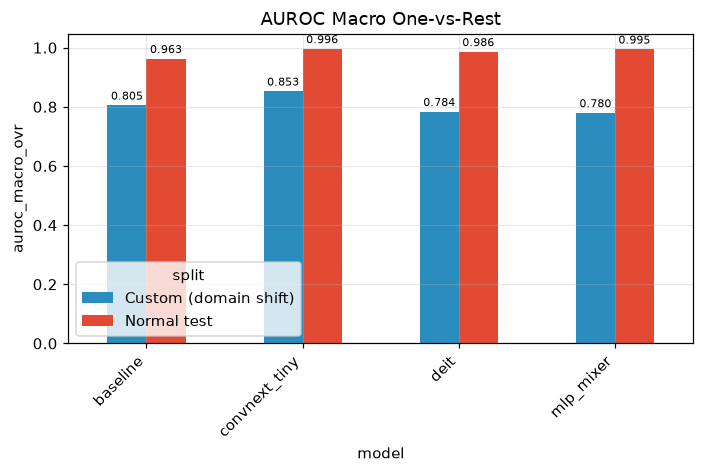

In [23]:
if not prob_metrics.empty:
    view = prob_metrics.pivot_table(
        index="model", columns="split_label", values=["auroc_macro_ovr"])
    ev.show_table(view, "auroc_macro_ovr_only", TABLE_DIR)

    fig, ax = plt.subplots(figsize=(6.5, 4.4))
    piv = prob_metrics.pivot_table(index="model", columns="split", values="auroc_macro_ovr")
    piv = piv.rename(columns=SPLITS)
    piv.plot(kind="bar", ax=ax,
             color=[SPLIT_COLORS[NORMAL_SPLIT], SPLIT_COLORS[SHIFT_SPLIT]])
    ax.set_title("AUROC Macro One-vs-Rest"); ax.set_ylabel("auroc_macro_ovr"); ax.legend(title="split")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=7, padding=2)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout(); ev.savefig(fig, "auroc_macro_ovr", FIG_DIR, SAVE_FIGS); plt.show()
else:
    print("(nothing to plot)")

ece            
split_label   Custom (domain shift) Normal test
model                                          
baseline                     0.3704      0.0228
convnext_tiny                0.4590      0.0238
deit                         0.4986      0.0398
mlp_mixer                    0.5333      0.0404

saved tables\ece_only.xlsx
saved figures\ece.png


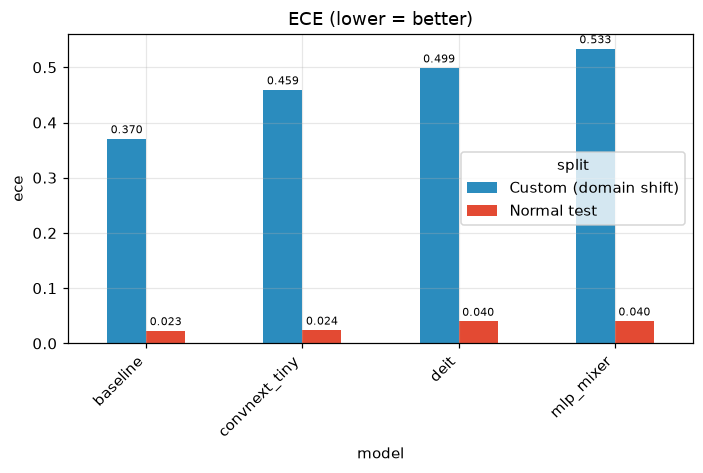

In [20]:
if not prob_metrics.empty:
    view = prob_metrics.pivot_table(
        index="model", columns="split_label", values=["ece"])
    ev.show_table(view, "ece_only", TABLE_DIR)

    fig, ax = plt.subplots(figsize=(6.5, 4.4))
    piv = prob_metrics.pivot_table(index="model", columns="split", values="ece")
    piv = piv.rename(columns=SPLITS)
    piv.plot(kind="bar", ax=ax,
             color=[SPLIT_COLORS[NORMAL_SPLIT], SPLIT_COLORS[SHIFT_SPLIT]])
    ax.set_title("ECE (lower = better)"); ax.set_ylabel("ece"); ax.legend(title="split")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=7, padding=2)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout(); ev.savefig(fig, "ece", FIG_DIR, SAVE_FIGS); plt.show()
else:
    print("(nothing to plot)")

sce            
split_label   Custom (domain shift) Normal test
model                                          
baseline                     0.3704     -0.0226
convnext_tiny                0.4575      0.0224
deit                         0.4921      0.0387
mlp_mixer                    0.5333      0.0398

saved tables\sce_only.xlsx
saved figures\sce.png


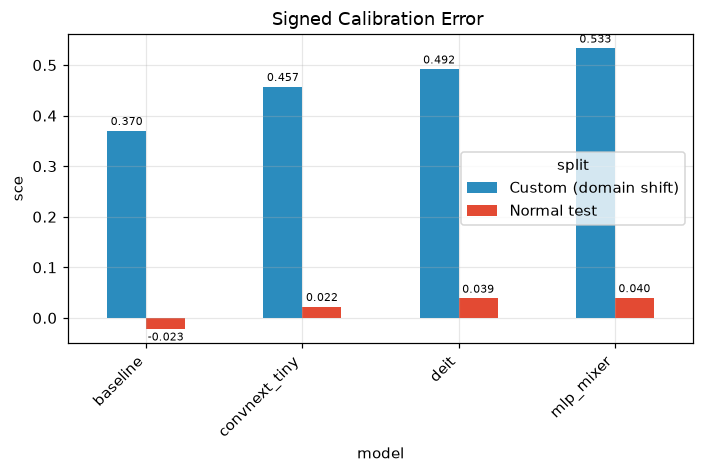

In [18]:
if not prob_metrics.empty:
    view = prob_metrics.pivot_table(
        index="model", columns="split_label", values=["sce"])
    ev.show_table(view, "sce_only", TABLE_DIR)

    fig, ax = plt.subplots(figsize=(6.5, 4.4))
    piv = prob_metrics.pivot_table(index="model", columns="split", values="sce")
    piv = piv.rename(columns=SPLITS)
    piv.plot(kind="bar", ax=ax,
             color=[SPLIT_COLORS[NORMAL_SPLIT], SPLIT_COLORS[SHIFT_SPLIT]])
    ax.set_title("Signed Calibration Error "); ax.set_ylabel("sce"); ax.legend(title="split")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=7, padding=2)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout(); ev.savefig(fig, "sce", FIG_DIR, SAVE_FIGS); plt.show()
else:
    print("(nothing to plot)")

In [16]:
# Domain-shift summary: tie the probability metrics to the hard-label ones per model.
if not prob_metrics.empty:
    core_shift = (metrics_long[metrics_long.split == SHIFT_SPLIT]
                  .set_index("model")[["accuracy", "macro_f1"]])
    prob_shift = (prob_metrics[prob_metrics.split == SHIFT_SPLIT]
                  .set_index("model")[["auroc_macro_ovr", "ece"]])
    combined = core_shift.join(prob_shift).sort_values("auroc_macro_ovr", ascending=False)
    print("Domain-shift set — hard-label + probability metrics:")
    ev.show_table(combined, "shift_hard_plus_prob_metrics", TABLE_DIR)

Domain-shift set — hard-label + probability metrics:


,accuracy,macro_f1,auroc_macro_ovr,ece
model,,,,
convnext_tiny,0.4080,0.4529,0.8527,0.4590
baseline,0.2902,0.2737,0.8053,0.3704
deit,0.3448,0.3758,0.7836,0.4986
mlp_mixer,0.3276,0.3759,0.7797,0.5333


saved tables\shift_hard_plus_prob_metrics.xlsx
